# How machines learn: regression

A handful of classic regression algorithms, implemented with plain numpy and run on one small synthetic dataset. Each builds on the last: a linear model, a tree that adapts to the data, a randomized tree, bagging many trees together, and an experiment on how tree depth causes overfitting.

Two words come up throughout:

- **Bias** is error from a model being too simple to capture the pattern. A straight line fit to a curve is wrong in the same way no matter how much data it sees.
- **Variance** is error from a model being too sensitive to the particular training sample. Train it on slightly different data and its predictions swing around.

Part two covers [classification](classification.ipynb), part three [unsupervised learning](unsupervised.ipynb).

In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def as_2d(X):
    X = np.asarray(X)
    return X.reshape(-1, 1) if X.ndim == 1 else X

def plot_fit(models, title=None):
    """Scatter the training data and draw each model's prediction curve."""
    plt.figure(figsize=(6, 4))
    plt.scatter(x_train, y_train, s=10, alpha=0.5, label="train")
    for label, model in models.items():
        plt.plot(grid, model.predict(grid), label=label)
    plt.legend()
    if title:
        plt.title(title)
    plt.show()

## The dataset

A 1D input `x` and a target `y = f(x) + noise`, where `f` mixes a smooth curve with a jump at `x = 1`. Linear regression will struggle with the jump; tree-based methods will not.

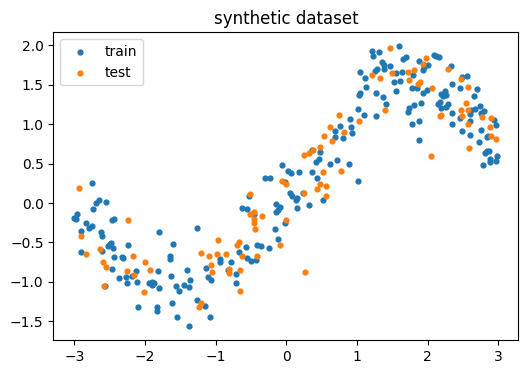

In [2]:
def make_dataset(n=300, noise=0.3, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-3, 3, n)
    y = np.sin(x) + 0.6 * (x > 1) + noise * rng.standard_normal(n)
    return x, y

def split(X, y, test_frac=0.3, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    cut = int(len(X) * test_frac)
    test, train = idx[:cut], idx[cut:]
    return X[train], y[train], X[test], y[test]

x, y = make_dataset()
x_train, y_train, x_test, y_test = split(x, y)
grid = np.linspace(x.min(), x.max(), 200)
results = {}  # test RMSE per model, compared at the end

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=12, label="train")
plt.scatter(x_test, y_test, s=12, label="test")
plt.legend()
plt.title("synthetic dataset")
plt.show()

## Linear regression

Fit `y = a*x + b` by least squares. It picks up the overall upward trend but can't bend for the curve or the jump.

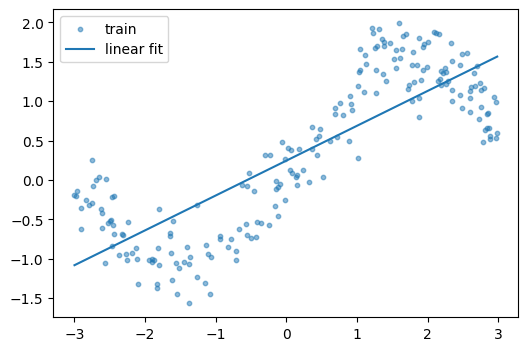

test RMSE: 0.5139162486335567


In [3]:
class LinearRegression:
    def fit(self, x, y):
        A = np.column_stack([x, np.ones_like(x)])  # columns: x, and 1 for the intercept
        self.coef_, *_ = np.linalg.lstsq(A, y, rcond=None)
        return self

    def predict(self, x):
        A = np.column_stack([x, np.ones_like(x)])
        return A @ self.coef_

lin = LinearRegression().fit(x_train, y_train)
plot_fit({"linear fit": lin})
results["linear regression"] = rmse(y_test, lin.predict(x_test))
print("test RMSE:", results["linear regression"])

What to look for: the line cuts straight through the wave, sitting above the data in some places and below it in others. That's bias: more data wouldn't help, because no straight line fits this shape.

## Decision tree regressor

A tree repeatedly cuts the input range in two. Here there's only one feature, so the only question is *where* to cut; this tree always cuts at the median, so each side gets half the points. A leaf predicts the mean of the targets that land in it. Splitting stops once a node holds `leaf_size` or fewer points.

The `Tree` class below holds the parts every tree in this notebook shares: recursing, stopping, and walking down to a leaf at prediction time. Each specific tree only has to say how it picks a split.

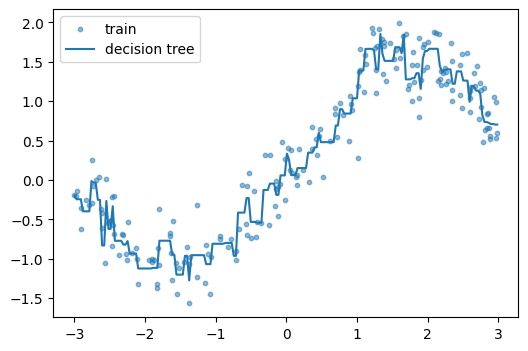

test RMSE: 0.3494747971696342


In [4]:
class Tree:
    """Shared skeleton: split the data in two, recurse on each side, stop at small or pure nodes.
    Subclasses only decide how to pick a split and what a leaf predicts."""

    def __init__(self, leaf_size=1):
        self.leaf_size = leaf_size

    def fit(self, X, y):
        self.tree_ = self._build(as_2d(X), y)
        return self

    def predict(self, X):
        return np.array([self._predict_row(row) for row in as_2d(X)])

    def _leaf_value(self, y):
        return y.mean()

    def _choose_split(self, X, y):
        """Return (feature, split value), or None to make this node a leaf."""
        raise NotImplementedError

    def _build(self, X, y):
        if len(y) <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": self._leaf_value(y)}

        choice = self._choose_split(X, y)
        if choice is None:
            return {"leaf": True, "value": self._leaf_value(y)}
        feat, split_val = choice
        left = X[:, feat] <= split_val
        if left.all() or (~left).all():  # split didn't separate anything
            return {"leaf": True, "value": self._leaf_value(y)}

        return {
            "leaf": False,
            "feature": feat,
            "split": split_val,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

    def _predict_row(self, row):
        node = self.tree_
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["split"] else node["right"]
        return node["value"]


class DecisionTree(Tree):
    def _choose_split(self, X, y):
        return 0, np.median(X[:, 0])

tree = DecisionTree(leaf_size=3).fit(x_train, y_train)
plot_fit({"decision tree": tree})
results["decision tree"] = rmse(y_test, tree.predict(x_test))
print("test RMSE:", results["decision tree"])

What to look for: a staircase that follows both the wave and the jump at `x = 1`. The small steps also chase some of the noise, which is the start of overfitting.

## Random tree regressor

Same tree, but each split cuts at a random point (halfway between two randomly chosen rows) instead of the median. On its own it's noisier than the decision tree. It's meant to be used inside an ensemble, where that randomness becomes useful, as the next section shows.

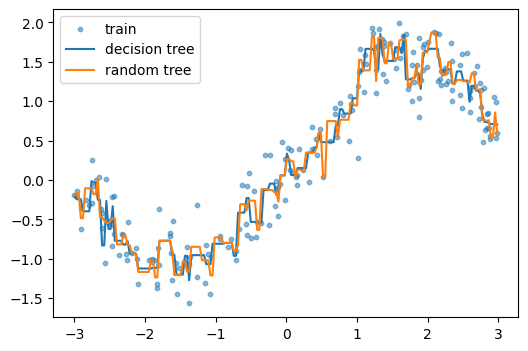

decision tree test RMSE: 0.3494747971696342
random tree test RMSE:   0.35916063273686466


In [5]:
class RandomTree(Tree):
    def __init__(self, leaf_size=1, seed=None):
        super().__init__(leaf_size)
        self.rng = np.random.default_rng(seed)

    def _choose_split(self, X, y):
        i, j = self.rng.choice(len(X), size=2, replace=False)
        return 0, (X[i, 0] + X[j, 0]) / 2

rtree = RandomTree(leaf_size=3, seed=1).fit(x_train, y_train)
plot_fit({"decision tree": tree, "random tree": rtree})
results["random tree"] = rmse(y_test, rtree.predict(x_test))
print("decision tree test RMSE:", results["decision tree"])
print("random tree test RMSE:  ", results["random tree"])

## Bagging

Train many copies of a learner, each on a random sample of the training rows drawn with replacement (a "bootstrap" sample), then average their predictions. A single random tree with `leaf_size=1` memorizes noise, so it has high variance. Each copy memorizes *different* noise, so averaging twenty of them cancels much of it out.

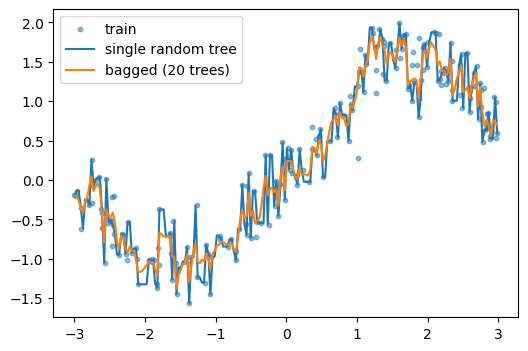

single tree test RMSE: 0.39663212211863746
bagged test RMSE:      0.34646553210558545


In [6]:
class BagLearner:
    """Train n_bags copies of a learner on bootstrap samples and average their predictions.
    With classify=True and 0/1 labels, the average is the fraction voting 1, so
    thresholding it at 0.5 is a majority vote."""

    def __init__(self, learner_cls, n_bags=20, learner_kwargs=None, classify=False, seed=0):
        self.learner_cls = learner_cls
        self.n_bags = n_bags
        self.learner_kwargs = learner_kwargs or {}
        self.classify = classify
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        n = len(X)
        kwargs = dict(self.learner_kwargs)
        takes_seed = "seed" in inspect.signature(self.learner_cls).parameters
        self.learners_ = []
        for _ in range(self.n_bags):
            idx = self.rng.integers(0, n, n)  # n rows drawn with replacement
            if takes_seed:  # give randomized learners their own seed so runs are reproducible
                kwargs["seed"] = self.rng.integers(2**32)
            self.learners_.append(self.learner_cls(**kwargs).fit(X[idx], y[idx]))
        return self

    def predict(self, X):
        avg = np.mean([learner.predict(X) for learner in self.learners_], axis=0)
        return (avg >= 0.5).astype(float) if self.classify else avg


single = RandomTree(leaf_size=1, seed=2).fit(x_train, y_train)
bagged = BagLearner(RandomTree, n_bags=20, learner_kwargs={"leaf_size": 1}, seed=2).fit(x_train, y_train)

plot_fit({"single random tree": single, "bagged (20 trees)": bagged})
results["random tree, leaf_size=1"] = rmse(y_test, single.predict(x_test))
results["bagged random trees"] = rmse(y_test, bagged.predict(x_test))
print("single tree test RMSE:", results["random tree, leaf_size=1"])
print("bagged test RMSE:     ", results["bagged random trees"])

What to look for: the single tree's curve is jagged, jumping to hit individual noisy points. The bagged curve is much smoother but still follows the jump.

## Bagging a stable learner

Bagging reduces variance, so it only helps learners whose predictions swing a lot from one training sample to the next. Linear regression gives nearly the same line for any bootstrap sample of this data. Its error is bias, and averaging twenty copies of the same line doesn't fix that.

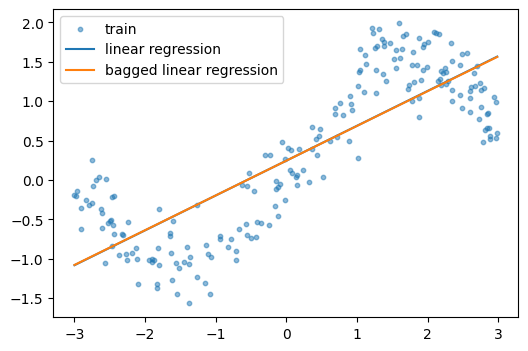

plain test RMSE:  0.5139162486335567
bagged test RMSE: 0.5139720432527918


In [7]:
bagged_lin = BagLearner(LinearRegression, n_bags=20, seed=0).fit(x_train, y_train)

plot_fit({"linear regression": lin, "bagged linear regression": bagged_lin})
results["bagged linear regression"] = rmse(y_test, bagged_lin.predict(x_test))
print("plain test RMSE: ", results["linear regression"])
print("bagged test RMSE:", results["bagged linear regression"])

What to look for: the two lines nearly overlap, and the RMSEs barely differ.

## Overfitting versus leaf size

Shrinking `leaf_size` lets the decision tree fit training points almost exactly, at the cost of doing worse on new data. Sweeping `leaf_size` and tracking in-sample (training) and out-of-sample (test) error separately shows the gap. Bagging the same tree at every `leaf_size` closes most of it.

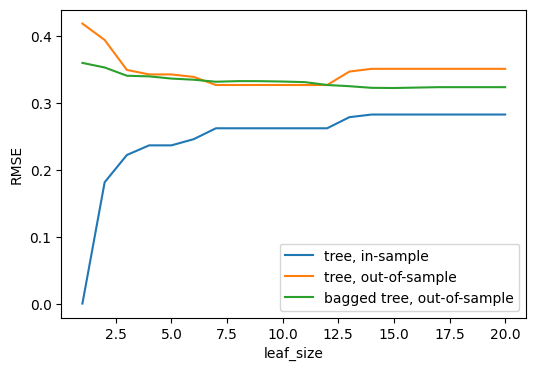

In [8]:
leaf_sizes = range(1, 21)
in_sample, out_sample, bagged_out_sample = [], [], []

for ls in leaf_sizes:
    t = DecisionTree(leaf_size=ls).fit(x_train, y_train)
    in_sample.append(rmse(y_train, t.predict(x_train)))
    out_sample.append(rmse(y_test, t.predict(x_test)))

    b = BagLearner(DecisionTree, n_bags=20, learner_kwargs={"leaf_size": ls}, seed=3).fit(x_train, y_train)
    bagged_out_sample.append(rmse(y_test, b.predict(x_test)))

plt.figure(figsize=(6, 4))
plt.plot(leaf_sizes, in_sample, label="tree, in-sample")
plt.plot(leaf_sizes, out_sample, label="tree, out-of-sample")
plt.plot(leaf_sizes, bagged_out_sample, label="bagged tree, out-of-sample")
plt.xlabel("leaf_size")
plt.ylabel("RMSE")
plt.legend()
plt.show()

What to look for: at `leaf_size=1` the in-sample error is near zero while the out-of-sample error is at its worst. That gap is overfitting. As leaves get bigger the two curves move toward each other.

## Results

In [9]:
for name, score in sorted(results.items(), key=lambda kv: kv[1]):
    print(f"{name:<28} {score:.3f}")

bagged random trees          0.346
decision tree                0.349
random tree                  0.359
random tree, leaf_size=1     0.397
linear regression            0.514
bagged linear regression     0.514


# Summary

Linear regression is stable but can only draw a straight line, so its error is bias. A decision tree can match any shape but overfits when leaves get small, so its error is variance. Random trees give up split quality in exchange for diversity, which is what makes them useful inside an ensemble. Bagging turns a handful of overfit, high-variance trees into one that generalizes better, but does nothing for linear regression, whose error was never about variance.